# Capstone C6 · A data engine: 10 human demonstrations → 500 generated → a policy that works
Collecting demonstrations is the most expensive part of robot learning. MimicGen (Mandlekar et al., 2023) showed
that a few human demos can be **multiplied**: most of a manipulation demo is defined *relative to an object*
("approach the cube from above, close, lift"; "move over the tray, open"). Move that piece of trajectory with the
object into a new layout, replay it in simulation, keep it if it works.

The plan:
1. a simulated human (S06 notebook 55: lag, tremor, hesitations) records **10** demos on the "single" scene;
2. we split each demo into a cube-relative and a tray-relative segment, and generate hundreds of new demos;
3. the S06 project's full recipe (16-step chunks, relative targets, two cameras) is trained on 10 human demos,
   100 generated and 500 generated, and evaluated on the same 50 new layouts.

In [1]:
import os, json, time, numpy as np, torch, matplotlib.pyplot as plt
from vlacourse import TableTop, evaluate, show_video, wilson
from vlacourse import showcase as sc
from vlacourse.torch_data import TableTopDataset
from vlacourse.chunk_policies import ChunkRegression, ChunkPolicy, train_policy
from vlacourse.mimicgen import record_source, segment, generate_parallel, replay_plan, _transform, _poses

device = "cuda" if torch.cuda.is_available() else "cpu"
ROOT = os.path.join("..", "data")
CAMS, ENV_KW = ("front", "wrist"), dict(scene="single", cameras=("front", "wrist"), image_size=(128, 128))
os.makedirs("results", exist_ok=True)

## 1. Ten human demonstrations
The simulated human is slow and shaky and fails often (we keep only its successes, like a real operator who
re-does a botched demo). We record the object poses at the start of each demo: the generator needs them.

In [2]:
env = TableTop(**ENV_KW, seed=0)
t0 = time.time()
demos, tries = record_source(env, 10, seed=0, out_dir=f"{ROOT}/c6_human10")
print(f"10 human demos from {tries} attempts ({10 / tries:.0%} of the human's attempts succeed), {time.time() - t0:.0f}s; "
      f"tasks: {[d['task']['type'] for d in demos]}")

10 human demos from 35 attempts (29% of the human's attempts succeed), 8s; tasks: ['place', 'pick', 'pick', 'pick', 'place', 'pick', 'place', 'place', 'pick', 'pick']


## 2. Object-centric segments, moved to new layouts
Left: one source demo, split where the cube is lifted. Right: the same demo re-targeted to three new layouts.
The cube segment moves *and rotates* with the cube (a cube looks the same every 90°, so we use the smallest turn);
the tray segment moves with the tray.

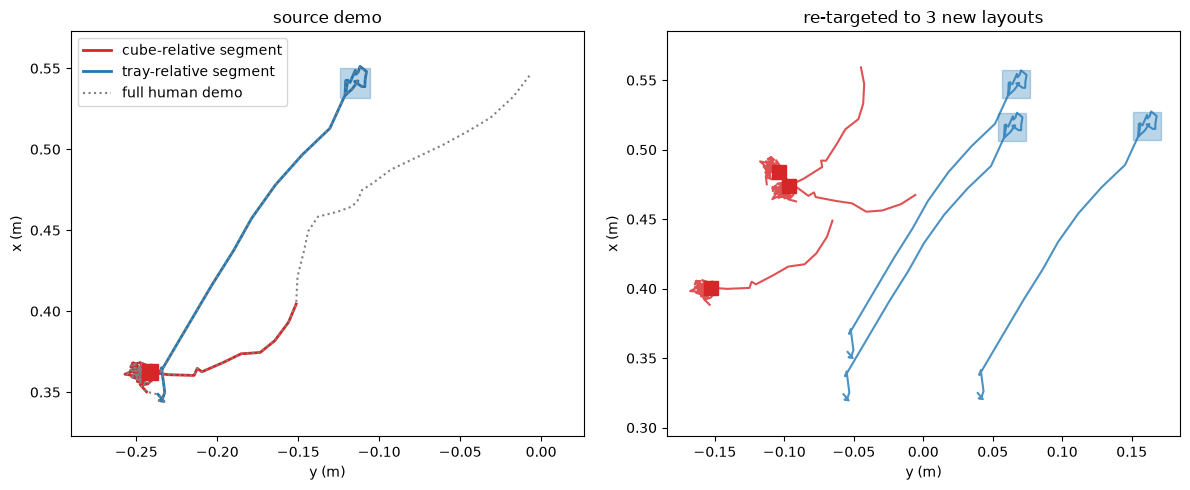

In [3]:
d = next(x for x in demos if x["task"]["type"] == "place")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for (frame, seg), col in zip(segment(d), ["tab:red", "tab:blue"]):
    ax[0].plot(seg[:, 1], seg[:, 0], "-", c=col, lw=2, label=f"{frame}-relative segment")
ax[0].plot(d["traj"][:, 1], d["traj"][:, 0], ":", c="grey", label="full human demo")
ax[0].plot(*d["poses"]["cube"][[1, 0]], "s", c="tab:red", ms=12); ax[0].plot(*d["poses"]["tray"][[1, 0]], "s", c="tab:blue", ms=22, alpha=0.3)
ax[0].set_title("source demo"); ax[0].legend(); ax[0].axis("equal")
rng = np.random.default_rng(3)
for k in range(3):
    dst =dict(cube=np.r_[rng.uniform([0.38, -0.2], [0.62, 0.0]), rng.uniform(-0.7, 0.7)], tray=rng.uniform([0.4, 0.05], [0.6, 0.2]))
    for (frame, seg), col in zip(segment(d), ["tab:red", "tab:blue"]):
        s2 = _transform(seg, frame, d["poses"], dst); ax[1].plot(s2[:, 1], s2[:, 0], "-", c=col, alpha=0.8)
    ax[1].plot(dst["cube"][1], dst["cube"][0], "s", c="tab:red", ms=10); ax[1].plot(dst["tray"][1], dst["tray"][0], "s", c="tab:blue", ms=20, alpha=0.3)
ax[1].set_title("re-targeted to 3 new layouts"); ax[1].axis("equal")
for a in ax:
    a.set_xlabel("y (m)"); a.set_ylabel("x (m)")
plt.tight_layout(); plt.show()

## 3. Generate
For each new random layout: pick a source demo with the same task type, move its segments, connect them with short
straight-line moves, replay in simulation, and keep the result only if the task succeeds. Parallel over CPU cores.

In [4]:
GEN = f"{ROOT}/c6_generated_500"
if not os.path.exists(f"{GEN}/meta.json"):
    generate_parallel(GEN, demos, 500, ENV_KW, seed=1, workers=8)
gm = json.load(open(f"{GEN}/meta.json"))
print(f"{gm['n_episodes']} generated demos from {gm['generated_from']} human demos; generation yield {gm['yield_']:.0%} "
      f"({gm['attempts']} replays tried)")

generated 500 demos from 10 sources: 502 attempts, yield 100%, 32s (8 workers)
500 generated demos from 10 human demos; generation yield 100% (502 replays tried)


## 4. Does generated data train a good policy?
Same network and recipe as S06 project 62 (16-step chunks, targets relative to the gripper, front + wrist cameras),
the same number of gradient steps for every row, the same 50 test layouts.

In [5]:
def train_eval(data, n, name):
    path = f"checkpoints/c6_{name}.pt"
    ds = TableTopDataset(data, episodes=range(n), horizon=16, cameras=CAMS, action_mode="rel")
    net = ChunkRegression(horizon=16, cameras=CAMS); torch.manual_seed(0)
    if os.path.exists(path):
        net.load_state_dict(torch.load(path, map_location=device)); net.to(device)
    else:
        epochs = int(np.clip(40 * 450 / n, 40, 1500))            # same number of gradient steps for every dataset size
        t0 = time.time(); train_policy(net, ds, epochs=epochs, lr=3e-4, device=device); torch.save(net.state_dict(), path)
        print(f"  {name}: trained {epochs} epochs in {time.time() - t0:.0f}s")
    pol = ChunkPolicy(net.eval(), ds, env, device, execute=8)
    return evaluate(env, pol, n_episodes=50, seed=50_000), pol

os.makedirs("checkpoints", exist_ok=True)
rows = {"10 human demos": (f"{ROOT}/c6_human10", 10), "100 generated (from the same 10)": (GEN, 100), "500 generated (from the same 10)": (GEN, 500)}
results, pols = {}, {}
for name, (data, n) in rows.items():
    results[name], pols[name] = train_eval(data, n, name.split(" (")[0].replace(" ", "_"))
    r = results[name]; print(f"{name:34s} success {r['success']:.0%}  CI [{r['ci'][0]:.2f}, {r['ci'][1]:.2f}]  per task {r['per_task']}")
ref = "../S06_Imitation_Learning/results/project5_pixel_bc.json"
if os.path.exists(ref):
    p5 = json.load(open(ref))
    print(f"for reference (S06 project 62, scripted expert): 50 demos {p5['full recipe, 50 demos']['success']:.0%}, "
          f"450 demos {p5['full recipe: 16-step chunk, relative targets, 2 cameras']['success']:.0%}")

  10_human_demos: trained 1500 epochs in 174s


10 human demos                     success 6%  CI [0.02, 0.16]  per task {'pick': 0.08, 'place': 0.04}


  100_generated: trained 180 epochs in 217s


100 generated (from the same 10)   success 50%  CI [0.37, 0.63]  per task {'pick': 0.76, 'place': 0.24}


  500_generated: trained 40 epochs in 255s


500 generated (from the same 10)   success 70%  CI [0.56, 0.81]  per task {'pick': 0.88, 'place': 0.52}
for reference (S06 project 62, scripted expert): 50 demos 66%, 450 demos 100%


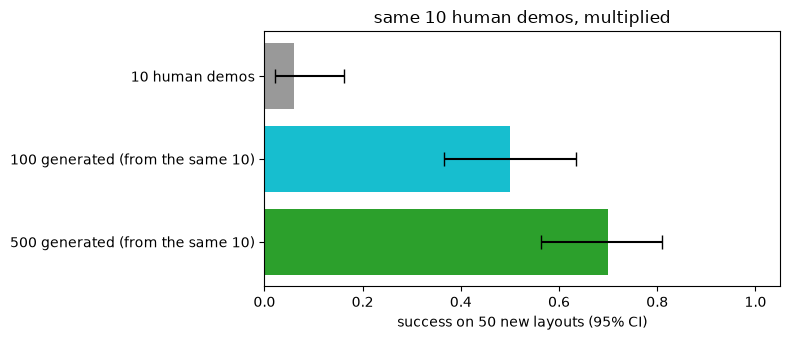

In [6]:
names = list(results)
s = np.array([results[n]["success"] for n in names]); lo, hi = np.array([results[n]["ci"] for n in names]).T
plt.figure(figsize=(8, 3.5)); plt.barh(names, s, xerr=np.clip([s - lo, hi - s], 0, None), capsize=5, color=["#999", "tab:cyan", "tab:green"])
plt.xlim(0, 1.05); plt.xlabel("success on 50 new layouts (95% CI)"); plt.gca().invert_yaxis(); plt.title("same 10 human demos, multiplied"); plt.tight_layout(); plt.show()
json.dump(dict(human_success_rate=10 / tries, gen_yield=gm["yield_"], results={n: dict(success=r["success"], ci=list(r["ci"])) for n, r in results.items()}),
          open("results/C6_data_engine.json", "w"), indent=1)

## 5. Share-ready videos
**The engine at work:** four generated demonstrations, each a re-targeted human demo on a layout the human never
saw. **The payoff:** the policy trained on 10 human demos vs the one trained on 500 generated, same test layout.

In [7]:
hd = TableTop(scene="single", cameras=CAMS, image_size=(128, 128), seed=0)
clips = []
for k in range(4):
    obs = hd.reset(seed=7_000 + k)
    src = next(x for x in demos if x["task"]["type"] == hd.task["type"])
    hd.start_video("showcase", (360, 640), fps=30)
    for a in replay_plan(hd, src, _poses(hd)):
        obs, _, done, info = hd.step(a)
        if done:
            break
    clips.append([sc.caption(f, f"generated demo {k + 1} · {hd.task['instruction']}", size=16) for f in hd.stop_video()])
engine = sc.title_card("Capstone C6 · Data engine", "10 human demonstrations → 500 generated in simulation\nMimicGen-style, MuJoCo · Franka Panda",
                       size=(720, 1280), n=60) + sc.grid(clips, cols=2, gap=0)
show_video(engine, fps=30, title="C6 data engine HD", width=960)
sc.export(engine, "outputs/C6_data_engine_hd.mp4", fps=30)

saved outputs/C6_data_engine_hd.mp4  (4.5 MB)


['outputs/C6_data_engine_hd.mp4']

In [8]:
ra, rb = results["500 generated (from the same 10)"], results["10 human demos"]
seed = sc.pick_seed(ra, rb, 50_000)
sc.compare(env, {"trained on 10 human demos": pols["10 human demos"], "trained on 500 generated": pols["500 generated (from the same 10)"]},
           seed=seed, size=(540, 640), title="C6 human vs generated data", footer="same 10 human demonstrations; right: multiplied by the data engine")

C6 human vs generated data: trained on 10 human demos: failed | trained on 500 generated: success


[False, True]

## Extensions (pick one for your submission)
- **Fewer sources:** generate from 1, 3 and 10 human demos. Where does diversity of the *sources* start to matter?
- **Harder tasks:** extend `segment` to stacking (cube-relative, then target-cube-relative) on the "full" scene.
- **Generation filters:** MimicGen keeps only successes. Also drop the slowest 20% of generated demos. Better policy?
- **Real-to-sim:** record 10 demos yourself with the keyboard teleop of S06 notebook 55 and feed them to the engine.